In [1]:
import pandas as pd
import numpy as np
import tqdm
from sklearn.model_selection import train_test_split
from datasets import Dataset, DatasetDict
from huggingface_hub import login

import ast
import re

# Silence transformers' informational/warning logs (e.g. legacy LayerNorm
# gamma/beta key-name notices when Trainer reloads the best checkpoint).
# Doesn't affect training/evaluation, only console noise.
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()

In [25]:
df = pd.read_csv("/kaggle/input/datasets/audreytheodoraphang/data-thesis/data_thesis.csv")

In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26379 entries, 0 to 26378
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   Unnamed: 0                     26379 non-null  int64 
 1   text_id                        26379 non-null  object
 2   annotators_id                  26379 non-null  object
 3   text                           26379 non-null  object
 4   topic                          26379 non-null  object
 5   is_noise_or_spam_text          26379 non-null  int64 
 6   toxicity                       26379 non-null  int64 
 7   polarized                      26379 non-null  int64 
 8   profanity_obscenity            26379 non-null  int64 
 9   threat_incitement_to_violence  26379 non-null  int64 
 10  insults                        26379 non-null  int64 
 11  identity_attack                26379 non-null  int64 
 12  sexually_explicit              26379 non-null  int64 
 13  c

In [27]:
df.head()

,Unnamed: 0,text_id,annotators_id,text,topic,is_noise_or_spam_text,toxicity,polarized,profanity_obscenity,threat_incitement_to_violence,insults,identity_attack,sexually_explicit,cleaned_text,processed_text
0,0,2026-01-01 00:00:00,"['7', '15']",Wajah Jurnalis Dibalut Perban Saat Melaporkan ...,UNKNOWN,0,0,0,0,0,0,0,0,Wajah jurnalis dibalut perban saat melaporkan ...,wajah jurnalis dibalut perban saat melaporkan ...
1,1,2026-01-10 00:00:00,"['7', '15']",Elektabilitas Paslon 02 sebentar lagi terjun b...,Disabilitas,0,0,1,0,0,0,0,0,Elektabilitas pasangan calon 02 sebentar lagi ...,elektabilitas pasangan calon sebentar lagi ter...
2,2,1-1001,"['10', '18']","Kristen, Hindu, Islam dapat perlakuan istimewa...",Kristen,0,0,1,0,0,0,0,0,"Kristen, Hindu, Islam dapat perlakuan istimewa...","kristen, hindu, islam dapat perlakuan istimewa..."
3,3,1-1004,"['10', '18']","Masyarakat Kristen, Hindu, Budha, dan etnis Ti...","Kristen, Tionghoa",0,0,0,0,0,0,0,0,"Masyarakat Kristen, Hindu, Buddha, dan etnis T...","masyarakat kristen, hindu, buddha, dan etnis t..."
4,4,1-1005,"['10', '18']",Cina Mengirimkan Satelit Penginderaan Jauh Bar...,Tionghoa,0,0,0,0,0,0,0,0,Cina mengirimkan satelit penginderaan jauh bar...,cina mengirimkan satelit penginderaan jauh bar...


In [28]:
def transform_datetime_id(text_id_str):
    # Regex to match the datetime pattern like 'YYYY-MM-DD HH:MM:SS'
    match = re.match(r'(\d+)-(\d{2})-(\d{2}) \d{2}:\d{2}:\d{2}', str(text_id_str))
    if match:
        year_part = match.group(1)
        month_part = int(match.group(2))
        day_part = int(match.group(3))

        if year_part == '2026':
            # For year 2026, format as month-day (e.g., '1-1')
            return f"{month_part}-{day_part}"
        else:
            # For other years, format as month-original_year (e.g., '2-8783')
            return f"{month_part}-{year_part}"
    else:
        return text_id_str  # Return original if pattern doesn't match

# Apply this transformation to the 'text_id' column of your DataFrame
df['text_id'] = df['text_id'].apply(transform_datetime_id)

In [29]:
cols = [
'is_noise_or_spam_text',
'toxicity',
'polarized',
'profanity_obscenity',
'threat_incitement_to_violence',
'insults',
'identity_attack',
'sexually_explicit'
]

for col in cols:
    df[col] = df[col].apply(lambda x: ast.literal_eval(x) if isinstance(x,str) else x)

In [30]:
df_main = df.copy()

In [31]:
print(df_main['is_noise_or_spam_text'].iloc[0])
print(type(df_main['is_noise_or_spam_text'].iloc[0]))

print(df_main['polarized'].iloc[0])
print(type(df_main['polarized'].iloc[0]))

print(df_main['profanity_obscenity'].iloc[0])
print(type(df_main['profanity_obscenity'].iloc[0]))

print(df_main['insults'].iloc[0])
print(type(df_main['insults'].iloc[0]))

print(df_main['sexually_explicit'].iloc[0])
print(type(df_main['sexually_explicit'].iloc[0]))

print(df_main['identity_attack'].iloc[0])
print(type(df_main['identity_attack'].iloc[0]))

print(df_main['toxicity'].iloc[0])
print(type(df_main['toxicity'].iloc[0]))

0
<class 'numpy.int64'>
0
<class 'numpy.int64'>
0
<class 'numpy.int64'>
0
<class 'numpy.int64'>
0
<class 'numpy.int64'>
0
<class 'numpy.int64'>
0
<class 'numpy.int64'>


In [32]:
df_main = df_main[df_main['is_noise_or_spam_text'] == 0]

In [33]:
df_main.isnull().sum()

Unnamed: 0                       0
text_id                          0
annotators_id                    0
text                             0
topic                            0
is_noise_or_spam_text            0
toxicity                         0
polarized                        0
profanity_obscenity              0
threat_incitement_to_violence    0
insults                          0
identity_attack                  0
sexually_explicit                0
cleaned_text                     0
processed_text                   0
dtype: int64

In [34]:
slang_dict = {
    "gk": "tidak",
    "ga": "tidak",
    "nggak": "tidak",
    "yg": "yang",
    "lu": "kamu",
    "loe": "kamu",
    "gw": "saya",
    "gue": "saya",
    "bgt": "banget",
    "dgn": "dengan",
    "krn": "karena",
    "aja": "saja",
    "trs": "terus"
}

In [35]:
import re

def normalize_slang(text, slang_dict):
    words = text.split()
    return " ".join([slang_dict.get(w.lower(), w) for w in words])

def preprocess_text(text, slang_dict, lowercase=True):
    if not isinstance(text, str):
        return ""

    # 1. remove username (@user)
    text = re.sub(r'@\w+', '', text)

    # 2. remove URL
    text = re.sub(r'http\S+|www\.\S+', '', text)

    # 3. remove numbers
    text = re.sub(r'\d+', '', text)

    # 4. remove unwanted symbols (keep .,!?)
    text = re.sub(r'[^\w\s.,!?]', '', text)

    # 5. normalize slang
    text = normalize_slang(text, slang_dict)

    # 6. normalize repeated chars (contoh: anjiiing -> anjiing)
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)

    # 7. lowercase (optional)
    if lowercase:
        text = text.lower()

    # 8. remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [36]:
from tqdm import tqdm
tqdm.pandas()

df_main["processed_text"] = (
    df_main["cleaned_text"]
    .fillna("")
    .astype(str)
    .progress_apply(
        lambda x: preprocess_text(x, slang_dict)
    )
)

100%|██████████| 26379/26379 [00:01<00:00, 20151.99it/s]


In [37]:
df_main['toxicity'].value_counts()

toxicity
0    23980
1     2399
Name: count, dtype: int64

In [38]:
df_main['profanity_obscenity'].value_counts()

profanity_obscenity
0    26018
1      361
Name: count, dtype: int64

In [39]:
df_main['insults'].value_counts()

insults
0    25315
1     1064
Name: count, dtype: int64

In [40]:
df_main['identity_attack'].value_counts()

identity_attack
0    25365
1     1014
Name: count, dtype: int64

# Stage 1

In [41]:
x = df_main['processed_text']
y = df_main['toxicity']

In [42]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, stratify = y, random_state=42)

In [43]:
train_df = pd.DataFrame({"processed_text": x_train, "label": y_train})
test_df = pd.DataFrame({"processed_text": x_test, "label": y_test})

In [44]:
# Handle imbalance for Stage 1 (toxicity: binary) via random oversampling of the minority class.
# Only the training split is resampled -- the test split must keep the original distribution
# so evaluation metrics stay meaningful.
print("Before oversampling:", train_df['label'].value_counts().to_dict())

label_counts = train_df['label'].value_counts()
majority_label = label_counts.idxmax()
majority_df = train_df[train_df['label'] == majority_label]
minority_df = train_df[train_df['label'] != majority_label]

minority_upsampled = minority_df.sample(n=len(majority_df), replace=True, random_state=42)

train_df = pd.concat([majority_df, minority_upsampled]).sample(frac=1, random_state=42).reset_index(drop=True)

print("After oversampling:", train_df['label'].value_counts().to_dict())

Before oversampling: {0: 19184, 1: 1919}
After oversampling: {1: 19184, 0: 19184}


In [45]:
dataset = DatasetDict({
    "train": Dataset.from_pandas(train_df),
    "test": Dataset.from_pandas(test_df)
})

In [46]:
from transformers import AutoTokenizer, Trainer, TrainingArguments, AutoModelForSequenceClassification
tokenizer = AutoTokenizer.from_pretrained("indolem/indobertweet-base-uncased")

config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

In [47]:
def tokenize(batch):
    return tokenizer(
        batch["processed_text"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

In [48]:
tokenized_datasets_1 = dataset.map(tokenize, batched=True)

tokenized_datasets_1 = tokenized_datasets_1.remove_columns(["processed_text"])
tokenized_datasets_1 = tokenized_datasets_1.rename_column("label", "labels")
tokenized_datasets_1.set_format("torch")

train_dataset_1 = tokenized_datasets_1["train"]
test_dataset_1 = tokenized_datasets_1["test"]

Map:   0%|          | 0/38368 [00:00<?, ? examples/s]

Map:   0%|          | 0/5276 [00:00<?, ? examples/s]

In [49]:
from transformers import AutoModelForSequenceClassification

model_s1 = AutoModelForSequenceClassification.from_pretrained(
    "indolem/indobertweet-base-uncased",
    num_labels=2
)

pytorch_model.bin:   0%|          | 0.00/445M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/445M [00:00<?, ?B/s]

In [50]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report, auc, roc_curve
def compute_metrics_s1(eval_pred):
    logits, labels = eval_pred
    preds = logits.argmax(axis=1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "f1": f1_score(labels, preds),
        "recall": recall_score(labels, preds),
        "precision": precision_score(labels, preds),
        "roc_auc": auc(roc_curve(labels, preds)[0], roc_curve(labels, preds)[1])
    }

In [51]:
args_s1 = TrainingArguments(
    output_dir="./baseline_s1",
    num_train_epochs=5,
    logging_steps=1,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    learning_rate = 1e-5,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    remove_unused_columns=False,
    disable_tqdm=False
)

trainer_s1 = Trainer(
    model=model_s1,
    args=args_s1,
    train_dataset=train_dataset_1,
    eval_dataset=test_dataset_1,
    compute_metrics=compute_metrics_s1
)

In [52]:

import sys
import datasets

# Matikan torchvision di runtime
if "torchvision" in sys.modules:
    del sys.modules["torchvision"]

# Paksa datasets menganggap torchvision tidak tersedia
datasets.config.TORCHVISION_AVAILABLE = False

print("TORCHVISION_AVAILABLE:", datasets.config.TORCHVISION_AVAILABLE)
print("torchvision loaded:", "torchvision" in sys.modules)

TORCHVISION_AVAILABLE: False
torchvision loaded: False


In [53]:
print("=== TRAINER ===")
print("label_names:", trainer_s1.label_names)
print("remove_unused_columns:", trainer_s1.args.remove_unused_columns)

print("\n=== DATASET ===")
print(trainer_s1.train_dataset.column_names)

print("\n=== SAMPLE ===")
sample = trainer_s1.train_dataset[0]
print(sample.keys())
print("labels:", sample.get("labels"))

print("\n=== MODEL ===")
print(type(trainer_s1.model))

=== TRAINER ===
label_names: ['labels']
remove_unused_columns: False

=== DATASET ===
['labels', 'input_ids', 'token_type_ids', 'attention_mask']

=== SAMPLE ===
dict_keys(['labels', 'input_ids', 'token_type_ids', 'attention_mask'])
labels: tensor(1)

=== MODEL ===
<class 'transformers.models.bert.modeling_bert.BertForSequenceClassification'>


In [54]:
# Run this line first, then restart the runtime, and finally re-execute all cells up to this point.
# !pip install --upgrade --force-reinstall torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121

trainer_s1.train()

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,F1,Recall,Precision,Roc Auc
1,0.041084,0.913810,0.855572,0.461864,0.681250,0.349359,0.777135
2,0.662831,1.342533,0.887794,0.483421,0.577083,0.415916,0.747987
3,0.001601,1.499352,0.898029,0.482692,0.522917,0.448214,0.729244
4,0.000439,1.614969,0.901251,0.457856,0.458333,0.457380,0.701956
5,0.688381,1.652131,0.902767,0.467290,0.468750,0.465839,0.707478


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=11990, training_loss=0.2682729931082255, metrics={'train_runtime': 3556.5144, 'train_samples_per_second': 53.94, 'train_steps_per_second': 3.371, 'total_flos': 1.26188062150656e+16, 'train_loss': 0.2682729931082255, 'epoch': 5.0})

In [55]:
history = trainer_s1.state.log_history
train_loss = [x['loss'] for x in history if 'loss' in x]
val_loss = [x['eval_loss'] for x in history if 'eval_loss' in x]
epochs = [x['epoch'] for x in history if 'eval_loss' in x]

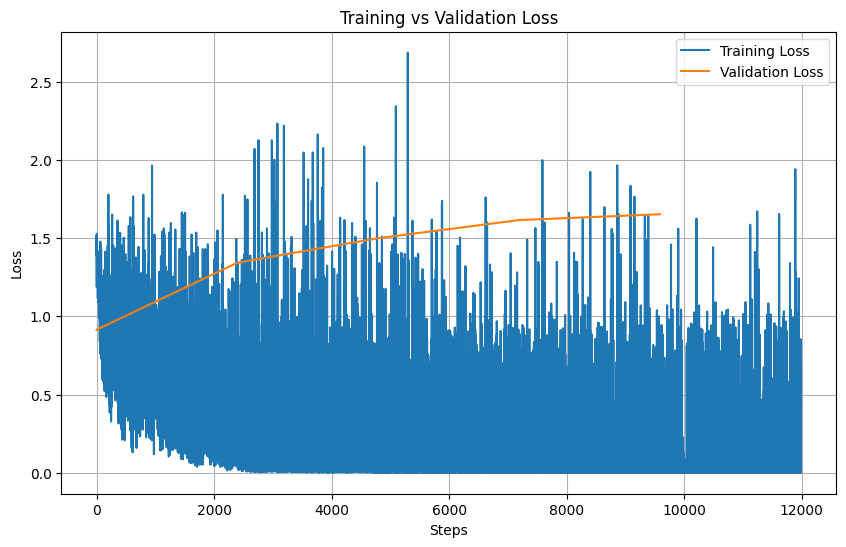

In [78]:
from matplotlib import pyplot as plt
plt.figure(figsize=(10, 6))
plt.plot(train_loss, label='Training Loss')
plt.plot(range(0, len(train_loss), len(train_loss)//len(val_loss)), val_loss, label='Validation Loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Steps')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

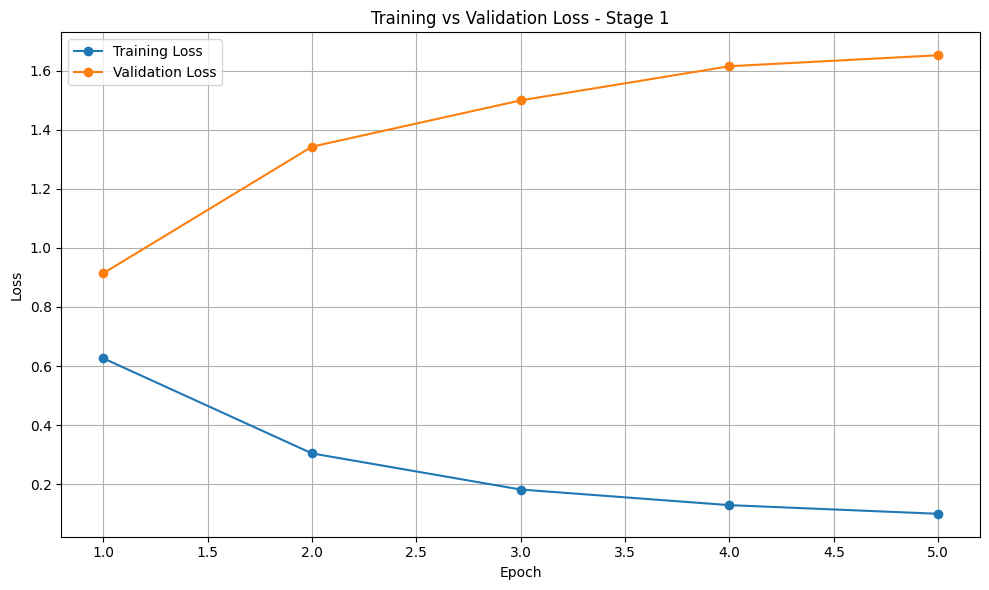

In [79]:
import matplotlib.pyplot as plt
import numpy as np

history_s1 = trainer_s1.state.log_history

# =========================
# Training Loss
# =========================

train_logs_s1 = [
    x for x in history_s1
    if 'loss' in x and 'eval_loss' not in x
]

train_epochs_s1 = [x['epoch'] for x in train_logs_s1]
train_losses_s1 = [x['loss'] for x in train_logs_s1]

# Kelompokkan training loss berdasarkan epoch
epoch_numbers_s1 = sorted(
    set(int(np.ceil(e)) for e in train_epochs_s1)
)

avg_train_loss_s1 = []

for epoch in epoch_numbers_s1:
    losses = [
        loss
        for e, loss in zip(train_epochs_s1, train_losses_s1)
        if int(np.ceil(e)) == epoch
    ]

    avg_train_loss_s1.append(np.mean(losses))


# =========================
# Validation Loss
# =========================

val_logs_s1 = [
    x for x in history_s1
    if 'eval_loss' in x
]

# Ambil validation loss PERTAMA untuk setiap epoch
val_loss_by_epoch_s1 = {}

for x in val_logs_s1:
    epoch = int(round(x['epoch']))

    if epoch not in val_loss_by_epoch_s1:
        val_loss_by_epoch_s1[epoch] = x['eval_loss']

val_epochs_s1 = sorted(val_loss_by_epoch_s1.keys())

val_losses_s1 = [
    val_loss_by_epoch_s1[epoch]
    for epoch in val_epochs_s1
]


# =========================
# Plot
# =========================

plt.figure(figsize=(10, 6))

plt.plot(
    epoch_numbers_s1,
    avg_train_loss_s1,
    marker='o',
    label='Training Loss'
)

plt.plot(
    val_epochs_s1,
    val_losses_s1,
    marker='o',
    label='Validation Loss'
)

plt.title('Training vs Validation Loss - Stage 1')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

In [57]:
evaluation_results1 = trainer_s1.evaluate()
print(evaluation_results1)

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


{'eval_loss': 0.905762255191803, 'eval_accuracy': 0.8586050037907506, 'eval_f1': 0.4663805436337625, 'eval_recall': 0.6791666666666667, 'eval_precision': 0.355119825708061, 'eval_roc_auc': 0.7778652349179871, 'eval_runtime': 30.6212, 'eval_samples_per_second': 172.299, 'eval_steps_per_second': 10.777, 'epoch': 5.0}


In [58]:
pred1 = trainer_s1.predict(test_dataset_1)
pred_label1 = pred1.predictions.argmax(axis=1)

y_test_numeric = y_test

print(classification_report(y_test_numeric, pred_label1))

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


              precision    recall  f1-score   support

           0       0.96      0.88      0.92      4796
           1       0.36      0.68      0.47       480

    accuracy                           0.86      5276
   macro avg       0.66      0.78      0.69      5276
weighted avg       0.91      0.86      0.88      5276



# stage 2

In [2]:
df_toxic = df_main[df_main["toxicity"] == 1].copy()

In [3]:
LABEL_COLS = [
    "insults",
    "identity_attack",
    "threat_incitement_to_violence",
    "profanity_obscenity",
    "sexually_explicit"
]

X = df_toxic["processed_text"]
y2 = df_toxic[LABEL_COLS]

In [4]:
train_df_s2, test_df_s2 = train_test_split(
    df_toxic,
    test_size=0.2,
    random_state=42
)

train_df_s2 = train_df_s2[["processed_text"] + LABEL_COLS].copy()
test_df_s2 = test_df_s2[["processed_text"] + LABEL_COLS].copy()

In [5]:
# Handle imbalance for Stage 2 (multi-label) via random oversampling of minority-label rows.
# For each label whose positive count is below the most frequent label's count, duplicate
# (with replacement) rows that carry that label until the gap is filled. Only the training
# split is resampled -- test_df_s2 keeps the original distribution.
def oversample_multilabel(df, label_cols, random_state=42):
    max_count = df[label_cols].sum().max()
    parts = [df]
    for col in label_cols:
        col_count = df[col].sum()
        n_needed = int(max_count - col_count)
        if n_needed > 0:
            minority_rows = df[df[col] == 1]
            if len(minority_rows) > 0:
                parts.append(minority_rows.sample(n=n_needed, replace=True, random_state=random_state))
    balanced = pd.concat(parts).sample(frac=1, random_state=random_state).reset_index(drop=True)
    return balanced

print("Before oversampling:", {c: int(train_df_s2[c].sum()) for c in LABEL_COLS})

train_df_s2 = oversample_multilabel(train_df_s2, LABEL_COLS, random_state=42)

print("After oversampling:", {c: int(train_df_s2[c].sum()) for c in LABEL_COLS})

Before oversampling: {'insults': 837, 'identity_attack': 795, 'threat_incitement_to_violence': 89, 'profanity_obscenity': 294, 'sexually_explicit': 50}
After oversampling: {'insults': 1194, 'identity_attack': 1273, 'threat_incitement_to_violence': 842, 'profanity_obscenity': 1131, 'sexually_explicit': 868}


In [6]:
train_df_s2["label"] = train_df_s2[LABEL_COLS].astype(float).values.tolist()
test_df_s2["label"] = test_df_s2[LABEL_COLS].astype(float).values.tolist()

train_df_s2 = train_df_s2[["processed_text", "label"]]
test_df_s2 = test_df_s2[["processed_text", "label"]]

In [7]:
dataset_s2 = DatasetDict({
    "train": Dataset.from_pandas(train_df_s2.reset_index(drop=True)),
    "test": Dataset.from_pandas(test_df_s2.reset_index(drop=True))
})

In [8]:
MODEL_NAME = "indolem/indobertweet-base-uncased"

tokenizer_s2 = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

In [9]:
def tokenize_s2(batch):
    return tokenizer_s2(
        batch["processed_text"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

tokenized_datasets_2 = dataset_s2.map(
    tokenize_s2,
    batched=True
)

tokenized_datasets_2 = tokenized_datasets_2.remove_columns(
    ["processed_text"]
)

tokenized_datasets_2 = tokenized_datasets_2.rename_column(
    "label",
    "labels"
)

tokenized_datasets_2.set_format("torch")
train_dataset_2 = tokenized_datasets_2["train"]
test_dataset_2 = tokenized_datasets_2["test"]

Map:   0%|          | 0/4039 [00:00<?, ? examples/s]

Map:   0%|          | 0/480 [00:00<?, ? examples/s]

In [10]:
model_s2 = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(LABEL_COLS),
    problem_type="multi_label_classification"
)

pytorch_model.bin:   0%|          | 0.00/445M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/445M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [11]:
import numpy as np
from sklearn.metrics import f1_score, roc_auc_score


def compute_metrics_s2(eval_pred):
    logits, labels = eval_pred


    preds = (logits > 0).astype(int)

    return {
        "f1_micro": f1_score(labels, preds, average="micro"),
        "f1_macro": f1_score(labels, preds, average="macro"),
        "accuracy": accuracy_score(labels, preds),
        "recall_micro": recall_score(
            labels,
            preds,
            average="micro",
            zero_division=0
        ),

        "precision_micro": precision_score(
            labels,
            preds,
            average="micro",
            zero_division=0
        )

    }

In [12]:
args_s2 = TrainingArguments(
    output_dir="./baseline_s2",
    num_train_epochs=5,
    logging_steps=1,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    learning_rate = 1e-5,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    disable_tqdm=False
)

trainer_s2 = Trainer(
    model=model_s2,
    args=args_s2,
    train_dataset=train_dataset_2,
    eval_dataset=test_dataset_2,
    compute_metrics=compute_metrics_s2
)

In [13]:
trainer_s2.train()

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,F1 Micro,F1 Macro,Accuracy,Recall Micro,Precision Micro
1,0.791281,0.794780,0.496718,0.463449,0.308333,0.443359,0.564677
2,0.338903,0.747523,0.540206,0.508239,0.337500,0.511719,0.572052
3,0.379618,0.714643,0.580707,0.537395,0.354167,0.593750,0.568224
4,0.371382,0.731682,0.574238,0.548154,0.360417,0.570312,0.578218
5,0.348648,0.731890,0.581643,0.553694,0.366667,0.587891,0.575526


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1265, training_loss=0.5320658495185875, metrics={'train_runtime': 386.4506, 'train_samples_per_second': 52.258, 'train_steps_per_second': 3.273, 'total_flos': 1328417721765120.0, 'train_loss': 0.5320658495185875, 'epoch': 5.0})

In [14]:
history_s2 = trainer_s2.state.log_history
train_loss_s2 = [x['loss'] for x in history_s2 if 'loss' in x]
val_loss_s2 = [x['eval_loss'] for x in history_s2 if 'eval_loss' in x]
epochs_s2 = [x['epoch'] for x in history_s2 if 'eval_loss' in x]

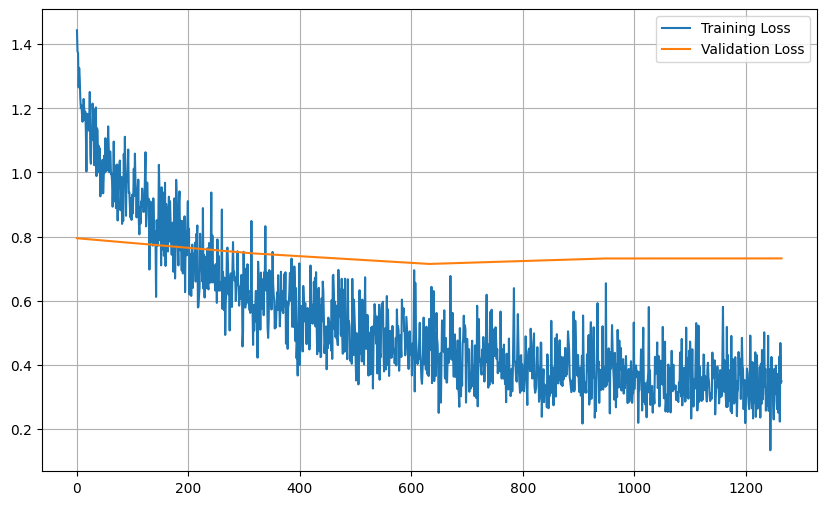

In [15]:
plt.figure(figsize=(10, 6))

plt.plot(train_loss_s2, label='Training Loss')

plt.plot(
    np.linspace(0, len(train_loss_s2)-1, len(val_loss_s2)),
    val_loss_s2,
    label='Validation Loss'
)

plt.legend()
plt.grid(True)
plt.show()

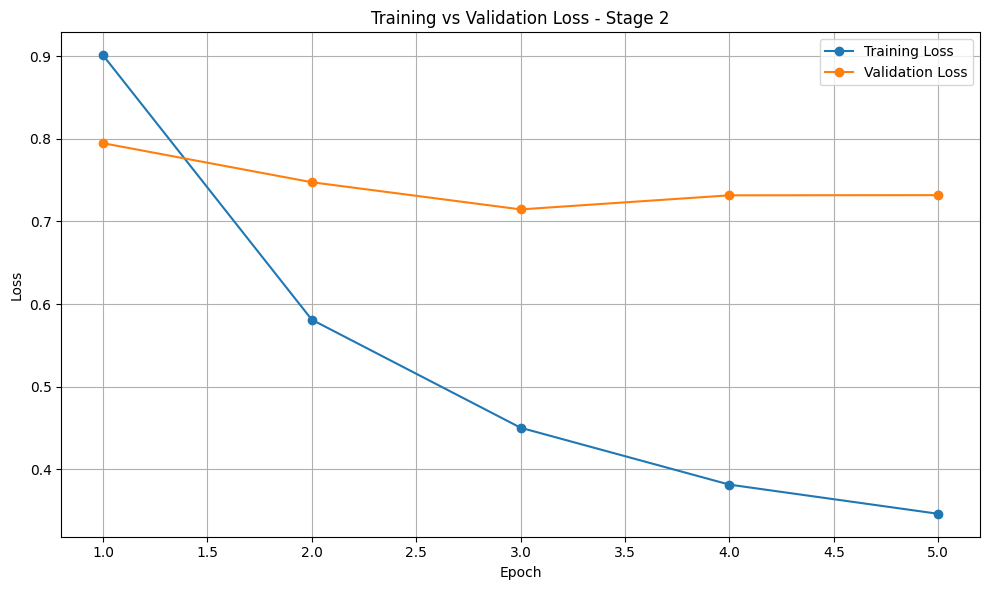

In [16]:
import matplotlib.pyplot as plt
import numpy as np

history_s2 = trainer_s2.state.log_history

# =========================
# Training Loss
# =========================

train_logs_s2 = [
    x for x in history_s2
    if 'loss' in x and 'eval_loss' not in x
]

train_epochs_s2 = [x['epoch'] for x in train_logs_s2]
train_losses_s2 = [x['loss'] for x in train_logs_s2]

# Kelompokkan training loss berdasarkan epoch
epoch_numbers_s2 = sorted(
    set(int(np.ceil(e)) for e in train_epochs_s2)
)

avg_train_loss_s2 = []

for epoch in epoch_numbers_s2:
    losses = [
        loss
        for e, loss in zip(train_epochs_s2, train_losses_s2)
        if int(np.ceil(e)) == epoch
    ]

    avg_train_loss_s2.append(np.mean(losses))


# =========================
# Validation Loss
# =========================

val_logs_s2 = [
    x for x in history_s2
    if 'eval_loss' in x
]

# Ambil validation loss PERTAMA untuk setiap epoch
val_loss_by_epoch_s2 = {}

for x in val_logs_s2:
    epoch = int(round(x['epoch']))

    if epoch not in val_loss_by_epoch_s2:
        val_loss_by_epoch_s2[epoch] = x['eval_loss']

val_epochs_s2 = sorted(val_loss_by_epoch_s2.keys())

val_losses_s2 = [
    val_loss_by_epoch_s2[epoch]
    for epoch in val_epochs_s2
]


# =========================
# Plot
# =========================

plt.figure(figsize=(10, 6))

plt.plot(
    epoch_numbers_s2,
    avg_train_loss_s2,
    marker='o',
    label='Training Loss'
)

plt.plot(
    val_epochs_s2,
    val_losses_s2,
    marker='o',
    label='Validation Loss'
)

plt.title('Training vs Validation Loss - Stage 2')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

In [17]:
evaluation_results2 = trainer_s2.evaluate()
print(evaluation_results2)

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


{'eval_loss': 0.7147701382637024, 'eval_f1_micro': 0.5807067812798472, 'eval_f1_macro': 0.5373952536549652, 'eval_accuracy': 0.3541666666666667, 'eval_recall_micro': 0.59375, 'eval_precision_micro': 0.5682242990654206, 'eval_runtime': 2.8203, 'eval_samples_per_second': 170.193, 'eval_steps_per_second': 10.637, 'epoch': 5.0}


In [18]:
pred2 = trainer_s2.predict(test_dataset_2)

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


In [19]:
logits = pred2.predictions

probs = 1 / (1 + np.exp(-logits))

threshold = 0.5
pred_label2 = (probs > threshold).astype(int)

y_true = pred2.label_ids

print(classification_report(y_true, pred_label2, target_names=LABEL_COLS))

                               precision    recall  f1-score   support

                      insults       0.61      0.57      0.59       218
              identity_attack       0.56      0.64      0.60       199
threat_incitement_to_violence       0.40      0.32      0.35        19
          profanity_obscenity       0.51      0.62      0.56        65
            sexually_explicit       0.83      0.45      0.59        11

                    micro avg       0.57      0.59      0.58       512
                    macro avg       0.58      0.52      0.54       512
                 weighted avg       0.57      0.59      0.58       512
                  samples avg       0.48      0.51      0.48       512



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in samples with no true labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in samples with no true nor predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [20]:
for i, label_name in enumerate(LABEL_COLS):

    print(f"\n===== {label_name} =====")

    print(
        classification_report(
            y_true[:, i],
            pred_label2[:, i]
        )
    )


===== insults =====
              precision    recall  f1-score   support

         0.0       0.66      0.69      0.68       262
         1.0       0.61      0.57      0.59       218

    accuracy                           0.64       480
   macro avg       0.63      0.63      0.63       480
weighted avg       0.64      0.64      0.64       480


===== identity_attack =====
              precision    recall  f1-score   support

         0.0       0.72      0.64      0.67       281
         1.0       0.56      0.64      0.60       199

    accuracy                           0.64       480
   macro avg       0.64      0.64      0.64       480
weighted avg       0.65      0.64      0.64       480


===== threat_incitement_to_violence =====
              precision    recall  f1-score   support

         0.0       0.97      0.98      0.98       461
         1.0       0.40      0.32      0.35        19

    accuracy                           0.95       480
   macro avg       0.69      0.65  